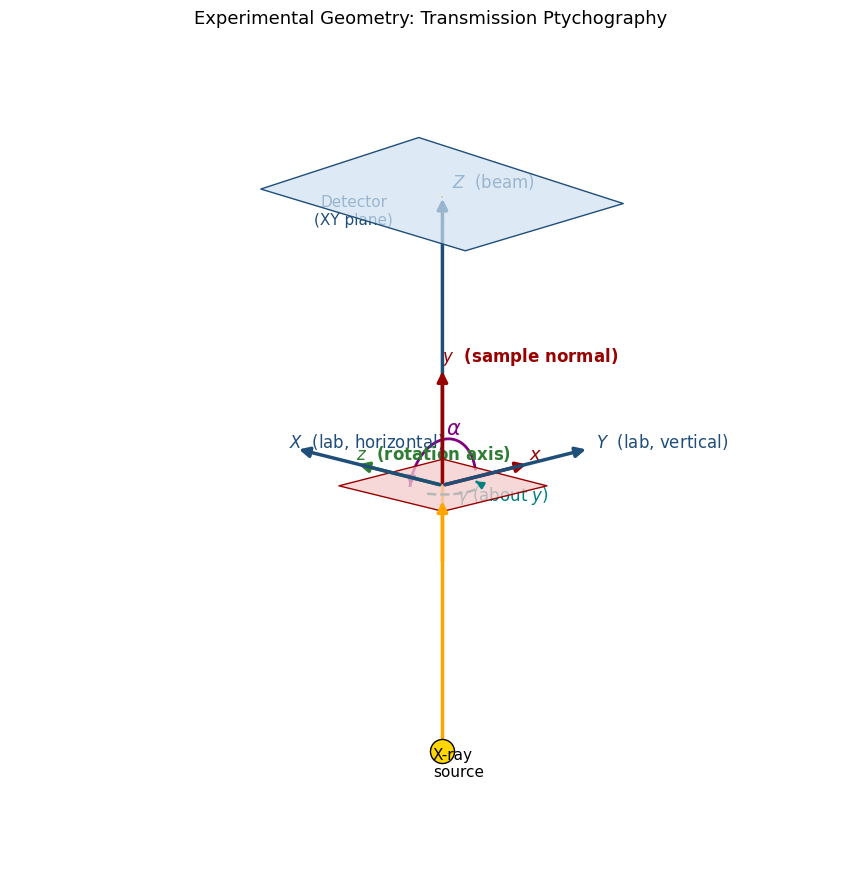

In [15]:
"""
Schematic of a transmission ptychography setup with lab and sample
coordinate systems labeled.

Lab frame (X, Y, Z):
  X: horizontal, along detector plane
  Y: vertical, along detector plane
  Z: beam direction (source -> detector)

Sample frame (x, y, z):
  x: in sample plane, perpendicular to rotation axis
  y: normal to sample plane (gamma rotates about this)
  z: along rotation axis (alpha rotates about this)

Rotation matrix R : x_sample -> X_lab
  R = [[-sin g,        0,        cos g     ],
       [ cos g cos a, -sin a,    sin g cos a],
       [ cos g sin a,  cos a,    sin g sin a]]
"""

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection, Line3DCollection
from matplotlib.patches import FancyArrowPatch
from mpl_toolkits.mplot3d import proj3d


# ---------- helper: 3D arrow ----------
class Arrow3D(FancyArrowPatch):
    def __init__(self, xs, ys, zs, *args, **kwargs):
        super().__init__((0, 0), (0, 0), *args, **kwargs)
        self._verts3d = xs, ys, zs

    def do_3d_projection(self, renderer=None):
        xs3d, ys3d, zs3d = self._verts3d
        xs, ys, zs = proj3d.proj_transform(xs3d, ys3d, zs3d, self.axes.M)
        self.set_positions((xs[0], ys[0]), (xs[1], ys[1]))
        return np.min(zs)


def add_arrow(ax, start, end, color, lw=2, mutation_scale=15, ls='-'):
    a = Arrow3D([start[0], end[0]],
                [start[1], end[1]],
                [start[2], end[2]],
                mutation_scale=mutation_scale, lw=lw,
                arrowstyle='-|>', color=color, linestyle=ls)
    ax.add_artist(a)


# ---------- rotation matrix (sample -> lab) ----------
def R_matrix(alpha, gamma):
    ca, sa = np.cos(alpha), np.sin(alpha)
    cg, sg = np.cos(gamma), np.sin(gamma)
    return np.array([[-sg,        0.0,    cg     ],
                     [ cg * ca,  -sa,    sg * ca ],
                     [ cg * sa,   ca,    sg * sa ]])


# ---------- setup ----------
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

alpha = np.deg2rad(0.0)   # nonzero tomographic angle
gamma = 0.0                # in-plane rotation, set to 0

R = R_matrix(alpha, gamma)

# sample-frame unit vectors expressed in lab frame
x_s = R @ np.array([1, 0, 0])
y_s = R @ np.array([0, 1, 0])
z_s = R @ np.array([0, 0, 1])

origin = np.array([0, 0, 0])

# ---------- lab axes ----------
L = 3.0
add_arrow(ax, origin, [L, 0, 0], color='#1f4e79', lw=2.5)  # X
add_arrow(ax, origin, [0, L, 0], color='#1f4e79', lw=2.5)  # Y
add_arrow(ax, origin, [0, 0, L + 1.5], color='#1f4e79', lw=2.5)  # Z
ax.text(L + 0.15, 0, 0, r'$X$  (lab, horizontal)', color='#1f4e79', fontsize=12)
ax.text(0, L + 0.15, 0, r'$Y$  (lab, vertical)', color='#1f4e79', fontsize=12)
ax.text(0, 0.2, L + 1.6, r'$Z$  (beam)', color='#1f4e79', fontsize=12)

# ---------- beam ----------
beam_start = np.array([0, 0, -4.0])
ax.plot([beam_start[0], 0], [beam_start[1], 0], [beam_start[2], 0],
        color='orange', lw=2.5, zorder=1)
add_arrow(ax, [0, 0, -1.2], [0, 0, -0.2], color='orange', lw=2.5)
# transmitted beam (dashed) continues to detector
ax.plot([0, 0], [0, 0], [0, L + 1.5],
        color='orange', lw=1.5, linestyle='--', zorder=1)

# ---------- source ----------
ax.scatter(*beam_start, color='gold', edgecolor='black', s=300, zorder=5)
ax.text(beam_start[0] + 0.2, beam_start[1], beam_start[2] - 0.4,
        'X-ray\nsource', fontsize=11, ha='left')

# ---------- detector (in XY plane, downstream) ----------
det_z = L + 1.5
det_w, det_h = 2.2, 1.7
det_verts = [[(-det_w, -det_h, det_z),
              ( det_w, -det_h, det_z),
              ( det_w,  det_h, det_z),
              (-det_w,  det_h, det_z)]]
det = Poly3DCollection(det_verts, facecolor='#cfe2f3',
                       edgecolor='#1f4e79', alpha=0.7)
ax.add_collection3d(det)
ax.text(0, -det_h - 0.25, det_z, 'Detector\n(XY plane)',
        ha='center', color='#1f4e79', fontsize=11)

# ---------- sample (a thin square slab in its xz plane, normal = y) ----------
s = 1.1     # half-side
# corners in sample frame (sample plane = xz plane in sample coords)
corners_s = np.array([[ s, 0,  s],
                      [-s, 0,  s],
                      [-s, 0, -s],
                      [ s, 0, -s]])
corners_lab = (R @ corners_s.T).T
sample = Poly3DCollection([corners_lab], facecolor='#f4cccc',
                          edgecolor='#990000', alpha=0.75)
ax.add_collection3d(sample)

# ---------- sample axes ----------
Ls = 1.8
add_arrow(ax, origin, Ls * x_s, color='#990000', lw=2.5)
add_arrow(ax, origin, Ls * y_s, color='#990000', lw=2.5)
add_arrow(ax, origin, Ls * z_s, color='#2e7d32', lw=2.5)  # rotation axis in green
ax.text(*(Ls * x_s + np.array([0.05, 0.05, 0.05])),
        r'$x$', color='#990000', fontsize=13, fontweight='bold')
ax.text(*(Ls * y_s + np.array([0.05, 0.05, 0.1])),
        r'$y$  (sample normal)', color='#990000', fontsize=12, fontweight='bold')
ax.text(*(Ls * z_s + np.array([0.05, 0.05, 0.05])),
        r'$z$  (rotation axis)', color='#2e7d32', fontsize=12, fontweight='bold')

# ---------- alpha rotation arc (about sample z-axis, in sample xy plane) ----------
# Draw an arc in the sample's xy-plane to indicate alpha
theta = np.linspace(np.deg2rad(10), np.deg2rad(170), 60)
r_arc = 0.7
arc_s = np.vstack([r_arc * np.cos(theta),
                   r_arc * np.sin(theta),
                   np.zeros_like(theta)])
arc_lab = R @ arc_s
ax.plot(arc_lab[0], arc_lab[1], arc_lab[2], color='purple', lw=2)
# arrowhead at the end of the arc
add_arrow(ax, arc_lab[:, -2], arc_lab[:, -1], color='purple', lw=2,
          mutation_scale=12)
ax.text(*(arc_lab[:, len(theta)//2] + np.array([0.05, 0.15, 0.05])),
        r'$\alpha$', color='purple', fontsize=15, fontweight='bold')

# ---------- gamma rotation arc (about sample y-axis, in sample xz plane) ----------
# Even though gamma = 0, indicate the sense of rotation for clarity
theta_g = np.linspace(np.deg2rad(200), np.deg2rad(340), 60)
r_g = 0.55
arc_g_s = np.vstack([r_g * np.cos(theta_g),
                     np.zeros_like(theta_g),
                     r_g * np.sin(theta_g)])
arc_g_lab = R @ arc_g_s
ax.plot(arc_g_lab[0], arc_g_lab[1], arc_g_lab[2], color='teal',
        lw=1.8, linestyle='--')
add_arrow(ax, arc_g_lab[:, -2], arc_g_lab[:, -1], color='teal', lw=1.8,
          mutation_scale=10)
ax.text(*(arc_g_lab[:, len(theta_g)//2] + np.array([0.05, -0.2, -0.1])),
        r'$\gamma$ (about $y$)', color='teal', fontsize=12)

# ---------- legend text ----------
# legend_text = (
#     "Transmission ptychography\n"
#     r"Shown at $\alpha = 30^\circ$, $\gamma = 0^\circ$"
#     "\n\n"
#     "Lab frame $(X, Y, Z)$ — blue\n"
#     "Sample frame $(x, y, z)$ — red / green\n\n"
#     r"$\alpha$: tomographic rotation about $z$"
#     "\n"
#     r"$\gamma$: in-plane rotation about $y$"
# )
# ax.text2D(0.02, 0.98, legend_text, transform=ax.transAxes,
#           fontsize=10, va='top',
#           bbox=dict(boxstyle='round', facecolor='white',
#                     edgecolor='gray', alpha=0.9))

# ---------- cosmetics ----------
ax.set_xlim(-3, 3.5)
ax.set_ylim(-3, 3.5)
ax.set_zlim(-4, 5)
ax.set_box_aspect([1, 1, 1.4])
ax.set_axis_off()
ax.view_init(elev=-15, azim=45)
plt.title('Experimental Geometry: Transmission Ptychography',
          fontsize=13, pad=10)
plt.tight_layout()
# plt.savefig('ptycho_schematic.png', dpi=200, bbox_inches='tight')
plt.show()

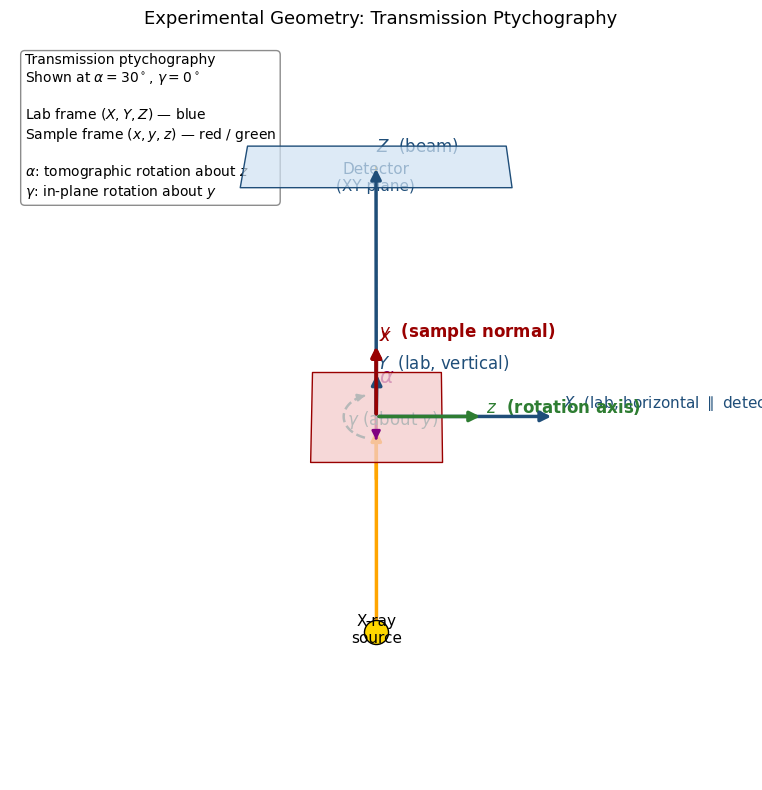

In [2]:
"""
Schematic of a transmission ptychography setup with lab and sample
coordinate systems labeled. Viewed so the beam (Z) runs horizontally.
"""

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from matplotlib.patches import FancyArrowPatch
from mpl_toolkits.mplot3d import proj3d


# ---------- helper: 3D arrow ----------
class Arrow3D(FancyArrowPatch):
    def __init__(self, xs, ys, zs, *args, **kwargs):
        super().__init__((0, 0), (0, 0), *args, **kwargs)
        self._verts3d = xs, ys, zs

    def do_3d_projection(self, renderer=None):
        xs3d, ys3d, zs3d = self._verts3d
        xs, ys, zs = proj3d.proj_transform(xs3d, ys3d, zs3d, self.axes.M)
        self.set_positions((xs[0], ys[0]), (xs[1], ys[1]))
        return np.min(zs)


def add_arrow(ax, start, end, color, lw=2, mutation_scale=15, ls='-'):
    a = Arrow3D([start[0], end[0]],
                [start[1], end[1]],
                [start[2], end[2]],
                mutation_scale=mutation_scale, lw=lw,
                arrowstyle='-|>', color=color, linestyle=ls)
    ax.add_artist(a)


# ---------- rotation matrix (sample -> lab) ----------
def R_matrix(alpha, gamma):
    ca, sa = np.cos(alpha), np.sin(alpha)
    cg, sg = np.cos(gamma), np.sin(gamma)
    return np.array([[-sg,        0.0,    cg     ],
                     [ cg * ca,  -sa,    sg * ca ],
                     [ cg * sa,   ca,    sg * sa ]])


# ---------- setup ----------
fig = plt.figure(figsize=(13, 8))
ax = fig.add_subplot(111, projection='3d')

alpha = np.deg2rad(30.0)   # nonzero tomographic angle
gamma = 0.0                # in-plane rotation, set to 0

R = R_matrix(alpha, gamma)

x_s = R @ np.array([1, 0, 0])
y_s = R @ np.array([0, 1, 0])
z_s = R @ np.array([0, 0, 1])

origin = np.array([0, 0, 0])

# ---------- lab axes ----------
L = 3.0
add_arrow(ax, origin, [L, 0, 0], color='#1f4e79', lw=2.5)        # X
add_arrow(ax, origin, [0, L, 0], color='#1f4e79', lw=2.5)        # Y
add_arrow(ax, origin, [0, 0, L + 1.5], color='#1f4e79', lw=2.5)  # Z
ax.text(L + 0.15, 0, 0.15, r'$X$  (lab, horizontal $\parallel$ detector)',
        color='#1f4e79', fontsize=11)
ax.text(0, L + 0.2, 0, r'$Y$  (lab, vertical)', color='#1f4e79', fontsize=12)
ax.text(0, 0.2, L + 1.7, r'$Z$  (beam)', color='#1f4e79', fontsize=12)

# ---------- beam ----------
beam_start = np.array([0, 0, -4.0])
ax.plot([beam_start[0], 0], [beam_start[1], 0], [beam_start[2], 0],
        color='orange', lw=2.5, zorder=1)
add_arrow(ax, [0, 0, -1.2], [0, 0, -0.2], color='orange', lw=2.5)
# transmitted beam (dashed) continues to detector
ax.plot([0, 0], [0, 0], [0, L + 1.5],
        color='orange', lw=1.5, linestyle='--', zorder=1)

# ---------- source ----------
ax.scatter(*beam_start, color='gold', edgecolor='black', s=300, zorder=5)
ax.text(beam_start[0], beam_start[1] - 0.6, beam_start[2],
        'X-ray\nsource', fontsize=11, ha='center')

# ---------- detector (in XY plane, downstream) ----------
det_z = L + 1.5
det_w, det_h = 2.2, 1.7
det_verts = [[(-det_w, -det_h, det_z),
              ( det_w, -det_h, det_z),
              ( det_w,  det_h, det_z),
              (-det_w,  det_h, det_z)]]
det = Poly3DCollection(det_verts, facecolor='#cfe2f3',
                       edgecolor='#1f4e79', alpha=0.7)
ax.add_collection3d(det)
ax.text(0, -det_h - 0.3, det_z, 'Detector\n(XY plane)',
        ha='center', color='#1f4e79', fontsize=11)

# ---------- sample (thin square slab in its xz plane; normal = y) ----------
s = 1.1
corners_s = np.array([[ s, 0,  s],
                      [-s, 0,  s],
                      [-s, 0, -s],
                      [ s, 0, -s]])
corners_lab = (R @ corners_s.T).T
sample = Poly3DCollection([corners_lab], facecolor='#f4cccc',
                          edgecolor='#990000', alpha=0.75)
ax.add_collection3d(sample)

# ---------- sample axes ----------
Ls = 1.8
add_arrow(ax, origin, Ls * x_s, color='#990000', lw=2.5)
add_arrow(ax, origin, Ls * y_s, color='#990000', lw=2.5)
add_arrow(ax, origin, Ls * z_s, color='#2e7d32', lw=2.5)
ax.text(*(Ls * x_s + np.array([0.05, 0.05, 0.05])),
        r'$x$', color='#990000', fontsize=13, fontweight='bold')
ax.text(*(Ls * y_s + np.array([0.05, 0.05, 0.1])),
        r'$y$  (sample normal)', color='#990000', fontsize=12, fontweight='bold')
ax.text(*(Ls * z_s + np.array([0.05, 0.05, 0.05])),
        r'$z$  (rotation axis)', color='#2e7d32', fontsize=12, fontweight='bold')

# ---------- alpha rotation arc (about sample z-axis, in sample xy plane) ----------
theta = np.linspace(np.deg2rad(10), np.deg2rad(170), 60)
r_arc = 0.7
arc_s = np.vstack([r_arc * np.cos(theta),
                   r_arc * np.sin(theta),
                   np.zeros_like(theta)])
arc_lab = R @ arc_s
ax.plot(arc_lab[0], arc_lab[1], arc_lab[2], color='purple', lw=2)
add_arrow(ax, arc_lab[:, -2], arc_lab[:, -1], color='purple', lw=2,
          mutation_scale=12)
ax.text(*(arc_lab[:, len(theta)//2] + np.array([0.05, 0.2, 0.05])),
        r'$\alpha$', color='purple', fontsize=15, fontweight='bold')

# ---------- gamma rotation arc (about sample y-axis, in sample xz plane) ----------
theta_g = np.linspace(np.deg2rad(200), np.deg2rad(340), 60)
r_g = 0.55
arc_g_s = np.vstack([r_g * np.cos(theta_g),
                     np.zeros_like(theta_g),
                     r_g * np.sin(theta_g)])
arc_g_lab = R @ arc_g_s
ax.plot(arc_g_lab[0], arc_g_lab[1], arc_g_lab[2], color='teal',
        lw=1.8, linestyle='--')
add_arrow(ax, arc_g_lab[:, -2], arc_g_lab[:, -1], color='teal', lw=1.8,
          mutation_scale=10)
ax.text(*(arc_g_lab[:, len(theta_g)//2] + np.array([0.05, -0.25, -0.1])),
        r'$\gamma$ (about $y$)', color='teal', fontsize=12)

# ---------- legend ----------
legend_text = (
    "Transmission ptychography\n"
    r"Shown at $\alpha = 30^\circ$, $\gamma = 0^\circ$"
    "\n\n"
    "Lab frame $(X, Y, Z)$ — blue\n"
    "Sample frame $(x, y, z)$ — red / green\n\n"
    r"$\alpha$: tomographic rotation about $z$"
    "\n"
    r"$\gamma$: in-plane rotation about $y$"
)
ax.text2D(0.02, 0.98, legend_text, transform=ax.transAxes,
          fontsize=10, va='top',
          bbox=dict(boxstyle='round', facecolor='white',
                    edgecolor='gray', alpha=0.9))

# ---------- cosmetics ----------
ax.set_xlim(-3, 3.5)
ax.set_ylim(-3, 3.5)
ax.set_zlim(-4.5, 5)
ax.set_box_aspect([1, 1, 1.4])
ax.set_axis_off()

# *** Key change: view from the side so Z runs horizontally ***
ax.view_init(elev=15, azim=-90)

plt.title('Experimental Geometry: Transmission Ptychography',
          fontsize=13, pad=10)
plt.tight_layout()
plt.savefig('ptycho_schematic.png', dpi=200, bbox_inches='tight')
plt.show()